In [1]:
# import pandas as pd
# import numpy as np
# from scipy.stats import chi2_contingency

# # ============================================================
# # 1. LOAD DATA
# # ============================================================
# sgb_list = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_results_for_engraftment_Oct26.csv')
# metadata = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/fmt_triads_filtered.csv')

# metaphlan_profiles = pd.read_csv(
#     '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/results/metaphlan_profiles_sgb.tsv',
#     sep='\t', header=[0, 1, 2]
# )
# sample_ids = [col[1] if col[1] != 'nan' else col[2] for col in metaphlan_profiles.columns]
# metaphlan_profiles.columns = sample_ids
# metaphlan_profiles = metaphlan_profiles.set_index(metaphlan_profiles.columns[0])
# metaphlan_profiles.index.name = 'clade_name'
# metaphlan_profiles.index = [s.split('|')[-1] if '|' in s else s for s in metaphlan_profiles.index]

# # ============================================================
# # 2. FILTER sgb_list
# # ============================================================
# datasets_to_exclude = ['NgS_2021', 'ShekarrizS_2025', 'CM_MORELIA', 'LeongK_2020', 'KousgaardS_2024', 'QuraishiMN_2026']
# excluded_pre_samples = metadata.loc[
#     metadata['dataset'].isin(datasets_to_exclude), 'single_pre_sample'
# ].values

# sgb_list_filtered = sgb_list[
#     ~sgb_list['pre_fmt_id'].isin(excluded_pre_samples) &
#     ~sgb_list['donor_id'].astype(str).str.contains(',') &
#     sgb_list['donor_id'].notna() &
#     ~sgb_list['donor_id'].astype(str).str.strip().isin(['', 'nan', 'cont'])
# ].copy()

# print(f"Rows before filter: {len(sgb_list)}")
# print(f"Rows after filter:  {len(sgb_list_filtered)}")

# # ============================================================
# # 3. HELPERS
# # ============================================================
# def parse_sgb_set(val):
#     if pd.isna(val) or str(val).strip() in ('', 'NaN', 'nan'):
#         return set()
#     return {s.strip() for s in str(val).split(',')}

# def meta_sgbs_for_sample(sample_id, restrict_to=None):
#     if sample_id not in metaphlan_profiles.columns:
#         return set()
#     sgbs = set(metaphlan_profiles.index[metaphlan_profiles[sample_id] > 0])
#     return sgbs & restrict_to if restrict_to is not None else sgbs

# def metaphlan_abund(sgb, sample_id):
#     if sgb in metaphlan_profiles.index and sample_id in metaphlan_profiles.columns:
#         return metaphlan_profiles.loc[sgb, sample_id]
#     return 0

# # ============================================================
# # 4. ENGRAFTMENT CONTINGENCY TABLE
# # ============================================================
# contingency_results = []

# for _, s_row in sgb_list_filtered.iterrows():
#     donor_id = s_row['donor_id']
#     pre_id   = s_row['pre_fmt_id']
#     post_id  = s_row['post_fmt_id']

#     donor_strain_sgbs      = parse_sgb_set(s_row['donor_sgbs'])
#     post_sgbs_all_profiled = parse_sgb_set(s_row['post_sgbs'])
#     shared_donor_post      = parse_sgb_set(s_row['shared_donor_post_sgbs'])

#     pre_sgbs_meta  = meta_sgbs_for_sample(pre_id,  restrict_to=donor_strain_sgbs)
#     post_sgbs_meta = meta_sgbs_for_sample(post_id, restrict_to=donor_strain_sgbs)
#     post_low_abund_sgbs = post_sgbs_meta - post_sgbs_all_profiled

#     A = B_absent = B_displaced = B_dropout = C = D_true = D_dropout = 0

#     for sgb in donor_strain_sgbs:
#         in_pre          = sgb in pre_sgbs_meta
#         strain_in_post  = sgb in shared_donor_post
#         species_in_post = sgb in post_sgbs_meta
#         is_dropout      = sgb in post_low_abund_sgbs

#         if in_pre:
#             if strain_in_post:          A += 1
#             elif is_dropout:            B_dropout += 1
#             elif not species_in_post:   B_absent += 1
#             else:                       B_displaced += 1
#         else:
#             if strain_in_post:          C += 1
#             elif is_dropout:            D_dropout += 1
#             else:                       D_true += 1

#     contingency_results.append({
#         'donor_id':            donor_id,
#         'pre_fmt_id':          pre_id,
#         'post_fmt_id':         post_id,
#         'A_pre_and_post':      A,
#         'B_absent':            B_absent,
#         'B_displaced':         B_displaced,
#         'B_dropout':           B_dropout,
#         'C_post_not_pre':      C,
#         'D_true':              D_true,
#         'D_dropout':           D_dropout,
#         'n_donor_strain_sgbs': len(donor_strain_sgbs),
#     })

# contingency_df = pd.DataFrame(contingency_results)
# print(contingency_df[['donor_id', 'pre_fmt_id', 'post_fmt_id',
#                        'A_pre_and_post', 'B_absent', 'B_displaced', 'B_dropout',
#                        'C_post_not_pre', 'D_true', 'D_dropout']].to_string())

# A = contingency_df['A_pre_and_post'].sum()
# B = (contingency_df['B_absent'] + contingency_df['B_displaced']).sum()
# C = contingency_df['C_post_not_pre'].sum()
# D = contingency_df['D_true'].sum()
# total_excluded = (contingency_df['B_dropout'] + contingency_df['D_dropout']).sum()

# table = np.array([[A, B], [C, D]])
# chi2, p, dof, expected = chi2_contingency(table)
# OR = (A * D) / (B * C)

# print("\n--- ENGRAFTMENT CONTINGENCY TABLE (dropouts excluded) ---")
# print(f"                       Strain in post   Strain NOT in post")
# print(f"SGB in pre-FMT:        {A:<16}   {B}  (absent={contingency_df['B_absent'].sum()}, displaced={contingency_df['B_displaced'].sum()})")
# print(f"SGB NOT in pre-FMT:    {C:<16}   {D}")
# print(f"\nTotal dropouts excluded: {total_excluded}  (B_dropout={contingency_df['B_dropout'].sum()}, D_dropout={contingency_df['D_dropout'].sum()})")
# print(f"\nChi2 = {chi2:.4f},  p = {p:.4e},  dof = {dof}")
# print(f"Odds ratio = {OR:.4f}")
# print(f"\nExpected frequencies:\n{expected}")

# # ============================================================
# # 5. COMPETITION ANALYSIS
# # ============================================================
# competition_results = []

# for _, s_row in sgb_list_filtered.iterrows():
#     donor_id = s_row['donor_id']
#     pre_id   = s_row['pre_fmt_id']
#     post_id  = s_row['post_fmt_id']

#     donor_strain_sgbs = parse_sgb_set(s_row['donor_sgbs'])
#     shared_donor_post = parse_sgb_set(s_row['shared_donor_post_sgbs'])
#     shared_pre_post   = parse_sgb_set(s_row['shared_post_pre_sgbs'])

#     pre_sgbs_meta  = meta_sgbs_for_sample(pre_id,  restrict_to=donor_strain_sgbs)
#     post_sgbs_meta = meta_sgbs_for_sample(post_id, restrict_to=donor_strain_sgbs)

#     # Only SGBs where both donor and pre-FMT recipient carry the species (true competition)
#     competition_sgbs = donor_strain_sgbs & pre_sgbs_meta

#     for sgb in competition_sgbs:
#         donor_replaced = sgb in shared_donor_post
#         pre_persisted  = sgb in shared_pre_post

#         if donor_replaced and pre_persisted:
#             outcome = 'ambiguous_both'
#         elif donor_replaced:
#             outcome = 'replaced'
#         elif pre_persisted:
#             outcome = 'not_replaced'
#         elif sgb in post_sgbs_meta:
#             outcome = 'dropout'
#         else:
#             outcome = 'species_lost'

#         donor_abund  = metaphlan_abund(sgb, donor_id)
#         pre_abund    = metaphlan_abund(sgb, pre_id)
#         donor_higher = donor_abund > pre_abund

#         competition_results.append({
#             'donor_id':     donor_id,
#             'pre_fmt_id':   pre_id,
#             'post_fmt_id':  post_id,
#             'sgb':          sgb,
#             'donor_abund':  donor_abund,
#             'pre_abund':    pre_abund,
#             'donor_higher': donor_higher,
#             'outcome':      outcome,
#         })

# competition_df = pd.DataFrame(competition_results)
# print(f"\nTotal competition SGBs: {len(competition_df)}")
# print(competition_df['outcome'].value_counts())

# analysis_df = competition_df[competition_df['outcome'].isin(['replaced', 'not_replaced', 'species_lost'])].copy()
# excluded_df = competition_df[~competition_df['outcome'].isin(['replaced', 'not_replaced', 'species_lost'])]
# print(f"\nExcluded (ambiguous/dropout): {len(excluded_df)}")

# analysis_df['donor_won'] = analysis_df['outcome'] == 'replaced'

# A = ((analysis_df['donor_higher'] == True)  & (analysis_df['donor_won'] == True)).sum()
# B = ((analysis_df['donor_higher'] == True)  & (analysis_df['donor_won'] == False)).sum()
# C = ((analysis_df['donor_higher'] == False) & (analysis_df['donor_won'] == True)).sum()
# D = ((analysis_df['donor_higher'] == False) & (analysis_df['donor_won'] == False)).sum()

# table = np.array([[A, B], [C, D]])
# chi2, p, dof, expected = chi2_contingency(table)
# OR = (A * D) / (B * C) if (B * C) > 0 else np.nan

# print("\n--- COMPETITION CONTINGENCY TABLE ---")
# print(f"                        Donor strain won   Donor strain did NOT win")
# print(f"Donor abund > Pre:      {A:<18}   {B}")
# print(f"Donor abund <= Pre:     {C:<18}   {D}")
# print(f"\nChi2 = {chi2:.4f},  p = {p:.4e},  dof = {dof}")
# print(f"Odds ratio = {OR:.4f}")
# print(f"\nExpected frequencies:\n{expected}")

Rows before filter: 606
Rows after filter:  492
                                          donor_id                        pre_fmt_id                       post_fmt_id  A_pre_and_post  B_absent  B_displaced  B_dropout  C_post_not_pre  D_true  D_dropout
0                                           D_2_S7                           11_0_S2                           11_6_S8               1        12            3          7               5      32          4
1                                           D_2_S7                           12_0_S7                          12_6_S10               3         4           12         22               5      14          4
2                                           D_3_S6                           16_0_S3                          16_6_S12              15         2            9          9              19      10          8
3                                      D_7Fryst_S7                           18_0_S6                          18_12_S1               2  

Rows before filter: 598
Rows after filter:  487

Donor SGB IDs in strain table: 1000
  ...also present in MetaPhlAn index: 1000
  example strain-table IDs: ['t__EUK4932', 't__SGB10068', 't__SGB10084']
  example MetaPhlAn IDs:    ['t__SGB6584', 't__SGB1815', 't__SGB9342']
Samples missing from MetaPhlAn profiles: 0

--- SECTION 4 COUNTS ---
Excluded, donor strain already shared with pre-FMT: 349
Excluded, post-side dropout: 9463  (B_dropout=3759, D_dropout=5704)
B breakdown: absent=1099, displaced=5479

=== ENGRAFTMENT (main: dropouts and pre-existing excluded) ===
[[2416, 6578],
 [5924, 12798]]   n = 27716
Chi2 = 65.7484, p = 5.1231e-16, dof = 1
Fisher exact p = 3.4142e-16
Odds ratio = 0.7935
Min expected count = 2706.38

=== ENGRAFTMENT (sensitivity: dropouts counted as non-engraftment) ===
[[2416, 10337],
 [5924, 18502]]   n = 37179
Chi2 = 135.3778, p = 2.7297e-31, dof = 1
Fisher exact p = 6.4265e-32
Odds ratio = 0.7300
Min expected count = 2860.76

Total competition SGBs: 13102
outco

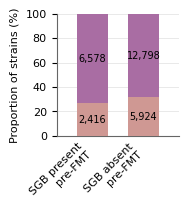

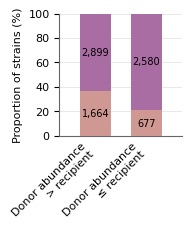

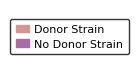

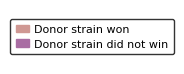

In [2]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, fisher_exact
import matplotlib as plt
plt.rcParams['svg.fonttype'] = 'none'


# ============================================================
# 0. CONFIG
# ============================================================
# Column in sgb_list holding SGBs whose strain is shared between donor and
# pre-FMT recipient (i.e. strain already present before FMT). CONFIRM THE NAME.
DONOR_PRE_COL = 'shared_donor_pre_sgbs'

# ============================================================
# 1. LOAD DATA
# ============================================================
sgb_list = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_results_for_engraftment_Oct26.csv')
metadata = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/triads_cleaned_1gbp.csv')

metaphlan_profiles = pd.read_csv(
    '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/results/metaphlan_profiles_sgb.tsv',
    sep='\t', header=[0, 1, 2]
)
sample_ids = [col[1] if col[1] != 'nan' else col[2] for col in metaphlan_profiles.columns]
metaphlan_profiles.columns = sample_ids
metaphlan_profiles = metaphlan_profiles.set_index(metaphlan_profiles.columns[0])
metaphlan_profiles.index.name = 'clade_name'
metaphlan_profiles.index = [s.split('|')[-1] if '|' in s else s for s in metaphlan_profiles.index]

if DONOR_PRE_COL not in sgb_list.columns:
    raise KeyError(f"'{DONOR_PRE_COL}' not in sgb_list. Columns are: {list(sgb_list.columns)}")

# ============================================================
# 2. FILTER sgb_list
# ============================================================
datasets_to_exclude = ['NgS_2021', 'ShekarrizS_2025', 'CM_MORELIA', 'LeongK_2020', 'KousgaardS_2024', 'QuraishiMN_2026']
excluded_pre_samples = metadata.loc[
    metadata['dataset'].isin(datasets_to_exclude), 'single_pre_sample'
].values

sgb_list_filtered = sgb_list[
    ~sgb_list['pre_fmt_id'].isin(excluded_pre_samples) &
    ~sgb_list['donor_id'].astype(str).str.contains(',') &
    sgb_list['donor_id'].notna() &
    ~sgb_list['donor_id'].astype(str).str.strip().isin(['', 'nan', 'cont'])
].copy()

print(f"Rows before filter: {len(sgb_list)}")
print(f"Rows after filter:  {len(sgb_list_filtered)}")

# ============================================================
# 3. HELPERS
# ============================================================
def parse_sgb_set(val):
    if pd.isna(val) or str(val).strip() in ('', 'NaN', 'nan'):
        return set()
    return {s.strip() for s in str(val).split(',')}

def meta_sgbs_for_sample(sample_id, restrict_to=None):
    if sample_id not in metaphlan_profiles.columns:
        return set()
    sgbs = set(metaphlan_profiles.index[metaphlan_profiles[sample_id] > 0])
    return sgbs & restrict_to if restrict_to is not None else sgbs

def metaphlan_abund(sgb, sample_id):
    if sgb in metaphlan_profiles.index and sample_id in metaphlan_profiles.columns:
        return metaphlan_profiles.loc[sgb, sample_id]
    return 0

def test_2x2(A, B, C, D, label):
    """Chi2 + Fisher exact on [[A,B],[C,D]]; Haldane-corrected OR if any zero cell."""
    table = np.array([[A, B], [C, D]])
    print(f"\n=== {label} ===")
    print(f"[[{A}, {B}],\n [{C}, {D}]]   n = {table.sum()}")
    if table.sum() == 0 or (table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any():
        print("Degenerate table (empty row/column); no test run.")
        return
    chi2, p_chi, dof, expected = chi2_contingency(table)
    _, p_fisher = fisher_exact(table)
    if (table == 0).any():
        OR = ((A + .5) * (D + .5)) / ((B + .5) * (C + .5))
        or_note = " (Haldane-corrected, zero cell)"
    else:
        OR = (A * D) / (B * C)
        or_note = ""
    print(f"Chi2 = {chi2:.4f}, p = {p_chi:.4e}, dof = {dof}")
    print(f"Fisher exact p = {p_fisher:.4e}")
    print(f"Odds ratio = {OR:.4f}{or_note}")
    print(f"Min expected count = {expected.min():.2f}")

# ============================================================
# 3b. SANITY CHECK: SGB ID overlap between strain table and MetaPhlAn
# ============================================================
all_donor_sgbs = set()
for v in sgb_list_filtered['donor_sgbs']:
    all_donor_sgbs |= parse_sgb_set(v)
overlap = all_donor_sgbs & set(metaphlan_profiles.index)
print(f"\nDonor SGB IDs in strain table: {len(all_donor_sgbs)}")
print(f"  ...also present in MetaPhlAn index: {len(overlap)}")
print(f"  example strain-table IDs: {sorted(all_donor_sgbs)[:3]}")
print(f"  example MetaPhlAn IDs:    {list(metaphlan_profiles.index[:3])}")
if len(overlap) < 0.9 * max(len(all_donor_sgbs), 1):
    print("  WARNING: low overlap, ID formats probably differ. Results below are unreliable.")

missing_samples = [s for col in ('donor_id', 'pre_fmt_id', 'post_fmt_id')
                   for s in sgb_list_filtered[col].unique() if s not in metaphlan_profiles.columns]
print(f"Samples missing from MetaPhlAn profiles: {len(set(missing_samples))}")

# ============================================================
# 4. ENGRAFTMENT CONTINGENCY TABLE
#    Rows: donor SGB present / absent in pre-FMT recipient (MetaPhlAn)
#    Cols: donor strain acquired post-FMT / not
#    Excluded: SGBs where the donor strain was already shared with the
#    pre-FMT recipient (cannot attribute to FMT), and post-side dropouts
#    (species seen by MetaPhlAn in post but no strain profile).
# ============================================================
contingency_results = []

for _, s_row in sgb_list_filtered.iterrows():
    donor_id = s_row['donor_id']
    pre_id   = s_row['pre_fmt_id']
    post_id  = s_row['post_fmt_id']

    donor_strain_sgbs      = parse_sgb_set(s_row['donor_sgbs'])
    post_sgbs_all_profiled = parse_sgb_set(s_row['post_sgbs'])
    shared_donor_post      = parse_sgb_set(s_row['shared_donor_post_sgbs'])
    shared_donor_pre       = parse_sgb_set(s_row[DONOR_PRE_COL])

    pre_sgbs_meta  = meta_sgbs_for_sample(pre_id,  restrict_to=donor_strain_sgbs)
    post_sgbs_meta = meta_sgbs_for_sample(post_id, restrict_to=donor_strain_sgbs)
    post_low_abund_sgbs = post_sgbs_meta - post_sgbs_all_profiled

    A = B_absent = B_displaced = B_dropout = C = D_true = D_dropout = 0
    n_preexisting = 0

    for sgb in donor_strain_sgbs:
        if sgb in shared_donor_pre:
            n_preexisting += 1          # donor strain already in recipient pre-FMT
            continue

        in_pre          = sgb in pre_sgbs_meta
        strain_in_post  = sgb in shared_donor_post
        species_in_post = sgb in post_sgbs_meta
        is_dropout      = sgb in post_low_abund_sgbs

        if in_pre:
            if strain_in_post:          A += 1
            elif is_dropout:            B_dropout += 1
            elif not species_in_post:   B_absent += 1
            else:                       B_displaced += 1
        else:
            if strain_in_post:          C += 1
            elif is_dropout:            D_dropout += 1
            else:                       D_true += 1

    contingency_results.append({
        'donor_id':            donor_id,
        'pre_fmt_id':          pre_id,
        'post_fmt_id':         post_id,
        'A_pre_and_post':      A,
        'B_absent':            B_absent,
        'B_displaced':         B_displaced,
        'B_dropout':           B_dropout,
        'C_post_not_pre':      C,
        'D_true':              D_true,
        'D_dropout':           D_dropout,
        'n_preexisting':       n_preexisting,
        'n_donor_strain_sgbs': len(donor_strain_sgbs),
    })

contingency_df = pd.DataFrame(contingency_results)

A = contingency_df['A_pre_and_post'].sum()
B = (contingency_df['B_absent'] + contingency_df['B_displaced']).sum()
C = contingency_df['C_post_not_pre'].sum()
D = contingency_df['D_true'].sum()
B_drop = contingency_df['B_dropout'].sum()
D_drop = contingency_df['D_dropout'].sum()

print("\n--- SECTION 4 COUNTS ---")
print(f"Excluded, donor strain already shared with pre-FMT: {contingency_df['n_preexisting'].sum()}")
print(f"Excluded, post-side dropout: {B_drop + D_drop}  (B_dropout={B_drop}, D_dropout={D_drop})")
print(f"B breakdown: absent={contingency_df['B_absent'].sum()}, displaced={contingency_df['B_displaced'].sum()}")

# Main: unresolvable dropouts excluded
test_2x2(A, B, C, D, "ENGRAFTMENT (main: dropouts and pre-existing excluded)")

eng_counts = dict(present_in=int(A), present_out=int(B),
                  absent_in=int(C),  absent_out=int(D))   # main analysis: dropouts excluded

# Sensitivity: dropouts counted as non-engraftment
test_2x2(A, B + B_drop, C, D + D_drop, "ENGRAFTMENT (sensitivity: dropouts counted as non-engraftment)")


# ============================================================
# 5. COMPETITION ANALYSIS
#    Competition SGBs: donor strain-profiled AND present in pre-FMT recipient (MetaPhlAn).
#    Pre-existing donor strain in the recipient is excluded (not a competitive win).
# ============================================================
competition_results = []

for _, s_row in sgb_list_filtered.iterrows():
    donor_id = s_row['donor_id']
    pre_id   = s_row['pre_fmt_id']
    post_id  = s_row['post_fmt_id']

    donor_strain_sgbs = parse_sgb_set(s_row['donor_sgbs'])
    post_profiled     = parse_sgb_set(s_row['post_sgbs'])
    shared_donor_post = parse_sgb_set(s_row['shared_donor_post_sgbs'])
    shared_pre_post   = parse_sgb_set(s_row['shared_post_pre_sgbs'])
    shared_donor_pre  = parse_sgb_set(s_row[DONOR_PRE_COL])

    pre_sgbs_meta  = meta_sgbs_for_sample(pre_id,  restrict_to=donor_strain_sgbs)
    post_sgbs_meta = meta_sgbs_for_sample(post_id, restrict_to=donor_strain_sgbs)

    competition_sgbs = donor_strain_sgbs & pre_sgbs_meta

    for sgb in competition_sgbs:
        if sgb in shared_donor_pre:
            outcome = 'preexisting_donor_strain'   # exclude
        else:
            donor_in_post = sgb in shared_donor_post
            pre_in_post   = sgb in shared_pre_post

            if donor_in_post and pre_in_post:
                outcome = 'ambiguous_both'         # exclude
            elif donor_in_post:
                outcome = 'replaced'               # donor wins
            elif pre_in_post:
                outcome = 'not_replaced'           # donor loses
            elif sgb not in post_sgbs_meta:
                outcome = 'species_lost'           # donor loses, but detection-limit prone
            elif sgb not in post_profiled:
                outcome = 'dropout'                # unresolvable, exclude
            else:
                outcome = 'other_strain'           # profiled, neither donor nor pre strain: donor loses

        donor_abund = metaphlan_abund(sgb, donor_id)
        pre_abund   = metaphlan_abund(sgb, pre_id)

        competition_results.append({
            'donor_id':     donor_id,
            'pre_fmt_id':   pre_id,
            'post_fmt_id':  post_id,
            'sgb':          sgb,
            'donor_abund':  donor_abund,
            'pre_abund':    pre_abund,
            'donor_higher': donor_abund > pre_abund,
            'outcome':      outcome,
        })

competition_df = pd.DataFrame(competition_results)
print(f"\nTotal competition SGBs: {len(competition_df)}")
print(competition_df['outcome'].value_counts())

def run_competition(df, label):
    df = df.copy()
    df['donor_won'] = df['outcome'] == 'replaced'
    A = ((df['donor_higher']) & (df['donor_won'])).sum()
    B = ((df['donor_higher']) & (~df['donor_won'])).sum()
    C = ((~df['donor_higher']) & (df['donor_won'])).sum()
    D = ((~df['donor_higher']) & (~df['donor_won'])).sum()
    print(f"\nRows: Donor abund > Pre / <= Pre.  Cols: Donor won / did not win")
    test_2x2(A, B, C, D, label)
    return dict(higher_won=int(A), higher_lost=int(B),
                lower_won=int(C),  lower_lost=int(D))

resolvable = ['replaced', 'not_replaced', 'other_strain']

# Main: species_lost excluded (most detection-limit prone)
comp_counts = run_competition(
    competition_df[competition_df['outcome'].isin(resolvable)],
    "COMPETITION (main: species_lost, dropout, ambiguous, pre-existing excluded)"
)
# Sensitivity: species_lost counted as donor loss (not plotted)
run_competition(
    competition_df[competition_df['outcome'].isin(resolvable + ['species_lost'])],
    "COMPETITION (sensitivity: species_lost counted as donor loss)"
)

import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# DATA (pulled from the analysis above)
# -----------------------------
engraftment_groups  = ["SGB present\npre-FMT", "SGB absent\npre-FMT"]
engraft_in_post     = [eng_counts['present_in'],  eng_counts['absent_in']]
engraft_not_in_post = [eng_counts['present_out'], eng_counts['absent_out']]

competition_groups = ["Donor abundance\n> recipient", "Donor abundance\n≤ recipient"]
donor_won     = [comp_counts['higher_won'],  comp_counts['lower_won']]
donor_not_won = [comp_counts['higher_lost'], comp_counts['lower_lost']]

print("Engraftment  in post:", engraft_in_post, " not in post:", engraft_not_in_post)
print("Competition  won:    ", donor_won,       " not won:    ", donor_not_won)

# -----------------------------
# STYLE
# -----------------------------
COLOR_BOTTOM = "#CF9893"
COLOR_TOP    = "#A96DA3"
BAR_WIDTH = 0.55
X_POS = [0, 0.9]


def normalize(bottoms, tops):
    bottoms = np.array(bottoms, dtype=float)
    tops = np.array(tops, dtype=float)
    totals = bottoms + tops
    return bottoms / totals * 100, tops / totals * 100


def add_count_labels(ax, x, bottoms_pct, tops_pct, bottoms_count, tops_count):
    for xi, bp, tp, bc, tc in zip(x, bottoms_pct, tops_pct, bottoms_count, tops_count):
        if bp > 0:
            ax.text(xi, bp / 2, f"{bc:,}", ha="center", va="center",
                    fontsize=7, color="black", fontweight="normal")
        if tp > 0:
            ax.text(xi, bp + tp / 2, f"{tc:,}", ha="center", va="center",
                    fontsize=7, color="black", fontweight="normal")


def style_axis(ax, x, labels):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8, rotation=45, ha="right")
    ax.set_xlim(x[0] - BAR_WIDTH * 1.15, x[-1] + BAR_WIDTH * 1.15)
    ax.set_ylim(0, 100)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.tick_params(axis="y", labelsize=8)
    ax.tick_params(axis="x", length=0)
    ax.yaxis.grid(True, linewidth=0.5, color="#e0e0e0", zorder=0)
    ax.set_axisbelow(True)
    ax.set_ylabel("Proportion of strains (%)", fontsize=8)


def stacked_panel(groups, bottoms, tops, label_bottom, label_top, save_path):
    bottom_pct, top_pct = normalize(bottoms, tops)

    fig, ax = plt.subplots(figsize=(40 / 25.4, 45 / 25.4))
    fig.subplots_adjust(left=0.20, right=0.98, bottom=0.28, top=0.97)

    ax.bar(X_POS, bottom_pct, width=BAR_WIDTH, color=COLOR_BOTTOM,
           label=label_bottom, zorder=3)
    ax.bar(X_POS, top_pct, width=BAR_WIDTH, bottom=bottom_pct, color=COLOR_TOP,
           label=label_top, zorder=3)

    add_count_labels(ax, X_POS, bottom_pct, top_pct, bottoms, tops)
    style_axis(ax, X_POS, groups)

    fig.savefig(save_path, format="svg", bbox_inches=None, pad_inches=0)
    plt.show()


def legend_panel(labels, save_path):
    fig, ax = plt.subplots(figsize=(35 / 25.4, 18 / 25.4))
    ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR_BOTTOM),
               plt.Rectangle((0, 0), 1, 1, color=COLOR_TOP)]
    ax.legend(handles, labels, loc="center", fontsize=8, frameon=True,
              edgecolor="black", facecolor="white", handlelength=1.2,
              handletextpad=0.5, borderpad=0.5, labelspacing=0.4)
    fig.savefig(save_path, format="svg", bbox_inches=None, pad_inches=0)
    plt.show()


# PLOT 1: ENGRAFTMENT
stacked_panel(engraftment_groups, engraft_in_post, engraft_not_in_post,
              "Strain in post-FMT", "Strain not in post-FMT",
              "engraftment_pres_abs.svg")

# PLOT 2: COMPETITION
stacked_panel(competition_groups, donor_won, donor_not_won,
              "Donor strain won", "Donor strain did not win",
              "strain_replacement_ra.svg")

# LEGENDS
legend_panel(["Donor Strain", "No Donor Strain"], "engraftment_legend.svg")
legend_panel(["Donor strain won", "Donor strain did not win"], "strain_replacement_legend.svg")